# **CAT & DOG CLASSIFICATION**
---

- Task : Classification
- Objective : Mengklasifikasikan citra hewan apakah termasuk kategori anjing (dog) atau kucing (cat) berdasarkan gambar
- Link Dataset : https://www.kaggle.com/datasets/anthonytherrien/dog-vs-cat

Klasifikasi citra anjing dan kucing merupakan salah satu studi kasus klasik dan fundamental dalam bidang Computer Vision dan Deep Learning. Meskipun manusia dapat dengan sangat mudah membedakan antara anjing dan kucing, tugas ini cukup menantang bagi komputer karena adanya variasi yang tinggi dalam hal ras, warna bulu, ukuran, pose tubuh, sudut pengambilan gambar, pencahayaan, serta latar belakang (background) yang kompleks.

Dalam praktikum ini, kita akan membangun dan membandingkan beberapa arsitektur model deep learning, mulai dari Multilayer Perceptron (MLP) sebagai baseline, Convolutional Neural Network (CNN) yang dirancang khusus untuk data spasial/gambar, hingga Transfer Learning menggunakan arsitektur modern Residual Network (ResNet-18) yang telah dilatih sebelumnya (pre-trained). Melalui studi kasus ini, mahasiswa diharapkan dapat memahami alur kerja pengolahan data citra, perancangan model, pelatihan, hingga evaluasi performa model klasifikasi.

![](https://media.licdn.com/dms/image/v2/C4E12AQGdg7fcjzJyEA/article-cover_image-shrink_720_1280/article-cover_image-shrink_720_1280/0/1607386301950?e=2147483647&v=beta&t=X4HkJm1LEoB5OMXunBIErAB9mBeJYflADiBtXs2yfPI)

In [1]:
# read, resize, plotting, splitting, encoding
import cv2
import os
import joblib
import shutil
import random
import numpy as np
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns
import time
from PIL import Image

# modelling
import tensorflow as tf
from keras.layers import Conv2D, BatchNormalization, Dropout, Flatten
from keras.models import Sequential, load_model, Model
from tensorflow.keras.optimizers import Adam

import torch
import torch.nn as nn
import torchvision.models as models
from torch.nn import functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.transforms import ToTensor
from dataclasses import dataclass

# evaluation
from sklearn.metrics import confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')

In [2]:
!pip install -q luwiji

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
from luwiji.cnn import illustration

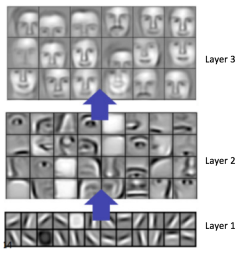

In [4]:
illustration.combination

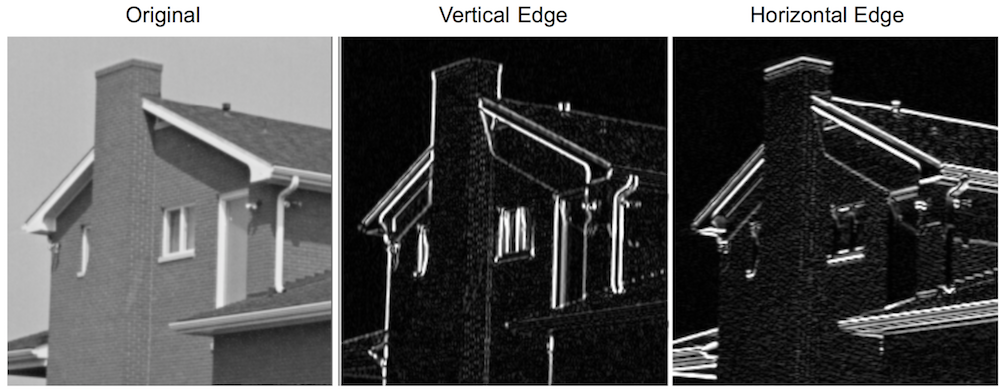

In [5]:
illustration.goal

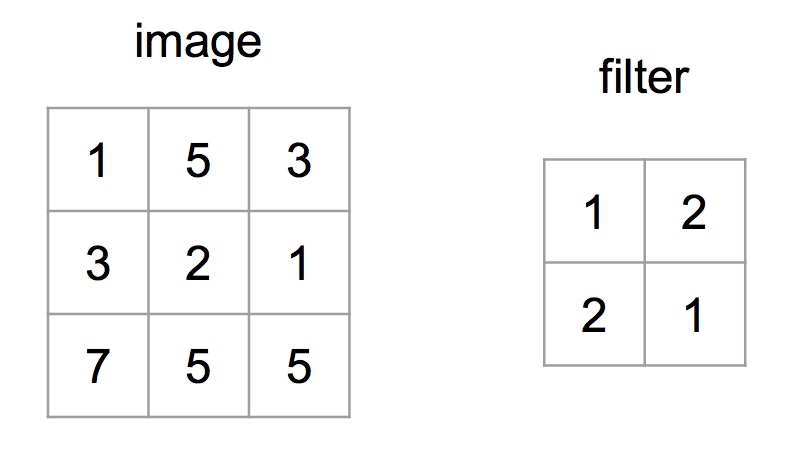

In [6]:
illustration.conv_ex1

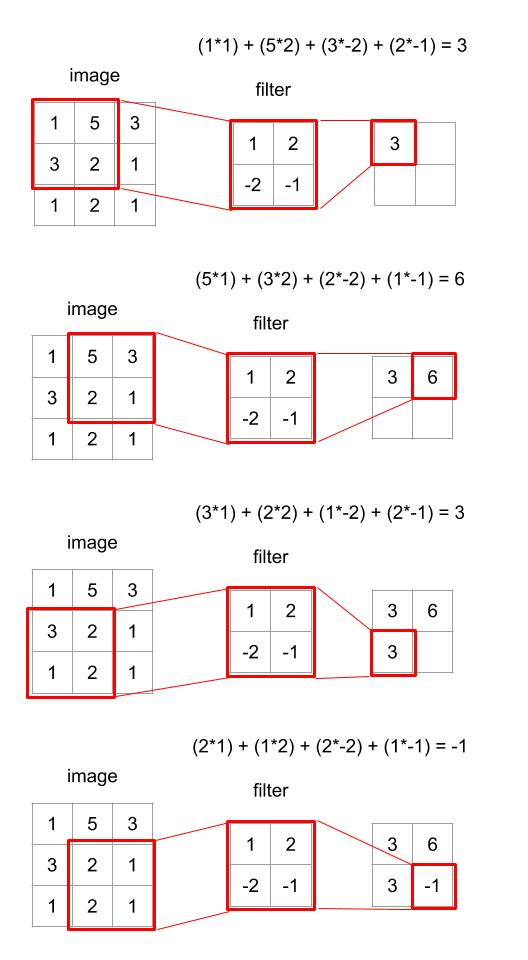

In [7]:
illustration.conv_ex2

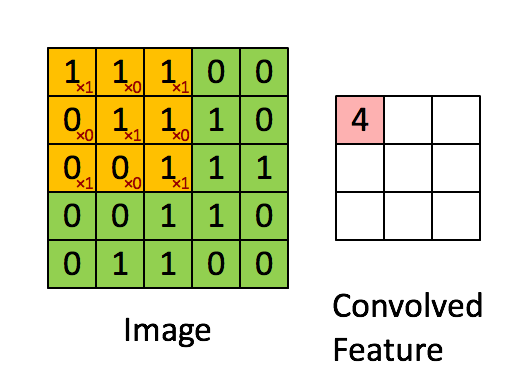

In [8]:
illustration.conv_ex3

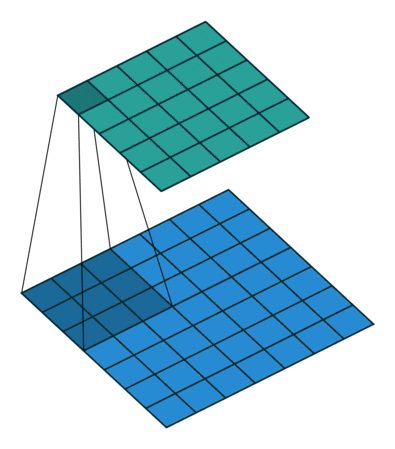

In [9]:
illustration.conv_ex4

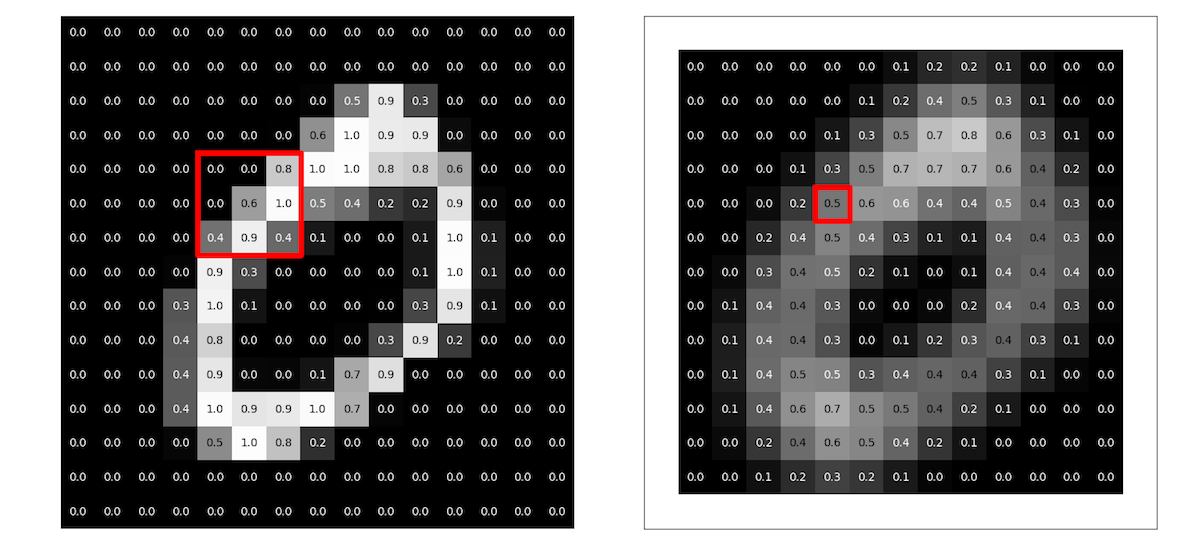

In [10]:
illustration.blur_avg

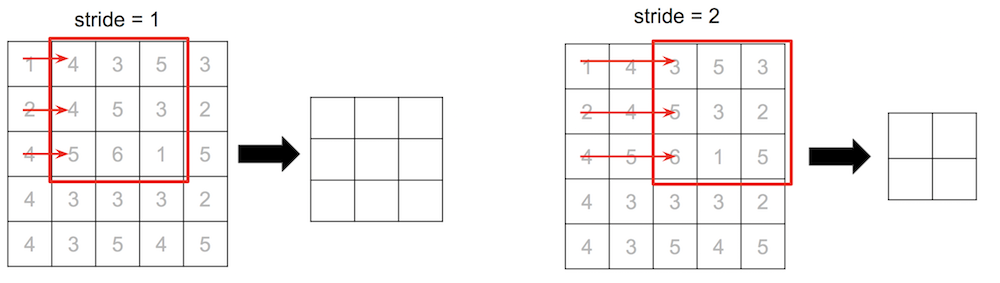

In [11]:
illustration.stride

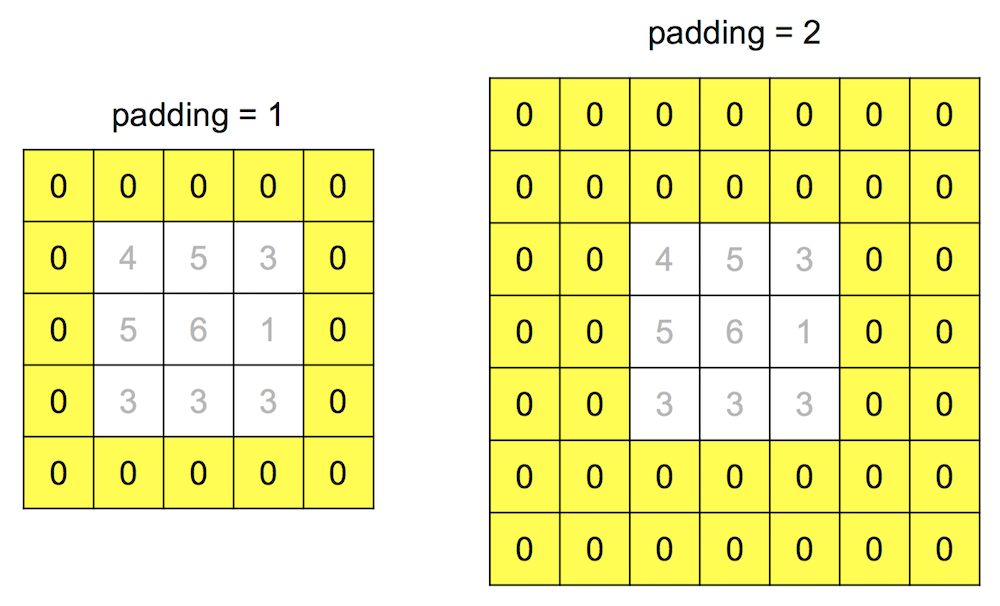

In [12]:
illustration.padding

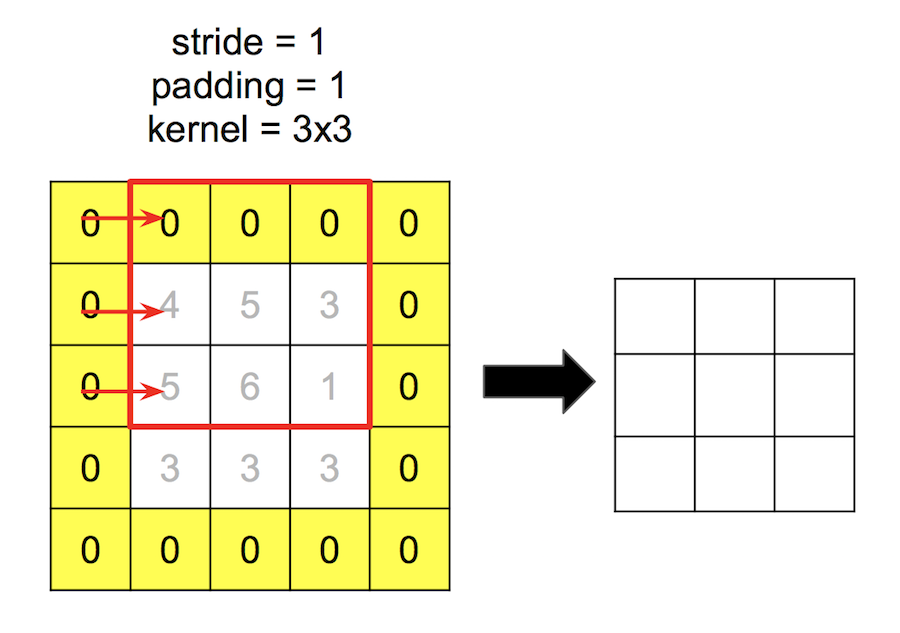

In [13]:
illustration.padding_same

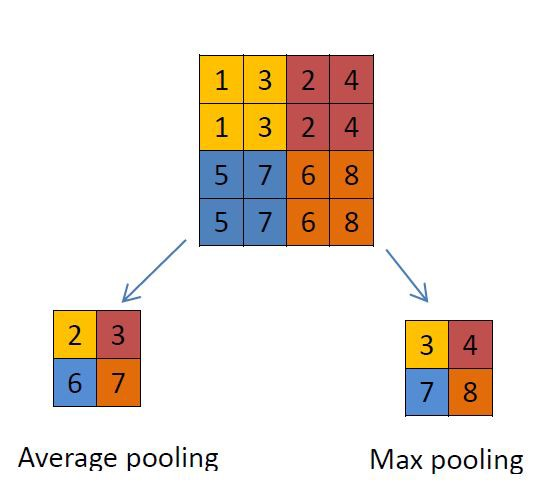

In [14]:
illustration.pooling

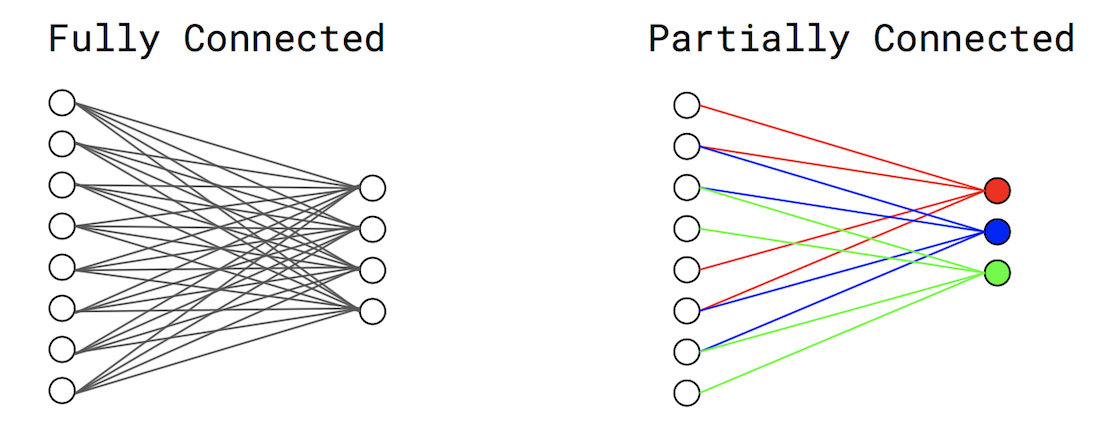

In [15]:
illustration.partial_con

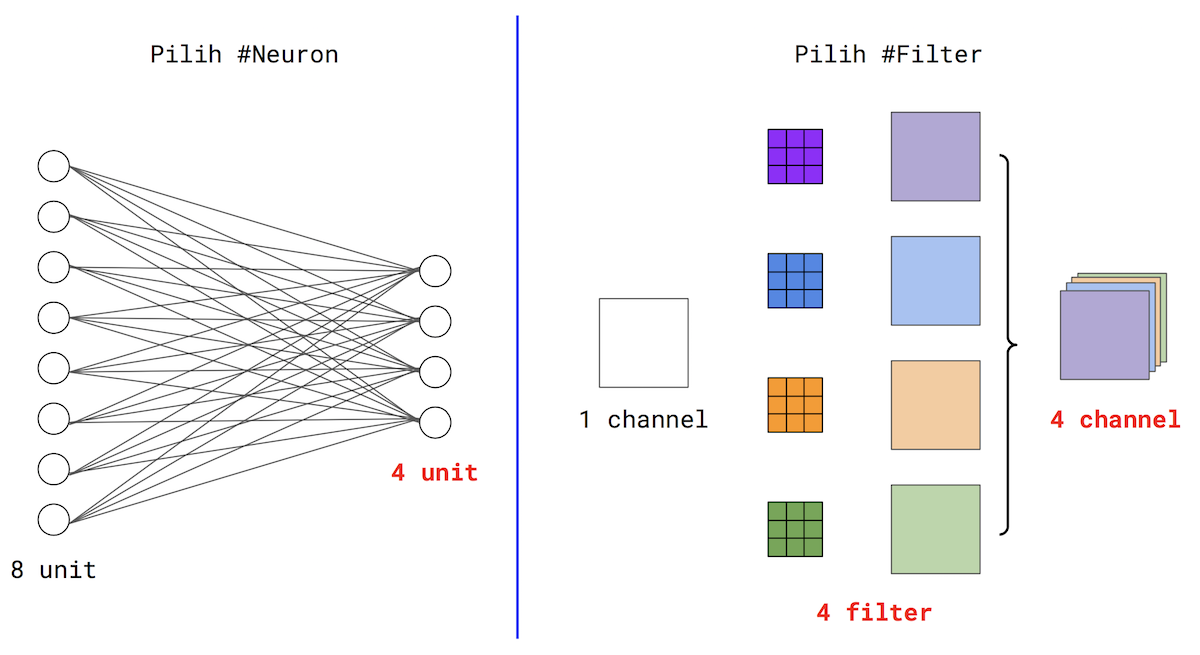

In [16]:
illustration.nn_vs_cnn

In [17]:
path = kagglehub.dataset_download("anthonytherrien/dog-vs-cat")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'dog-vs-cat' dataset.
Path to dataset files: /kaggle/input/dog-vs-cat


In [18]:
base_dir = '/kaggle/input/dog-vs-cat/animals'
original_dir = base_dir

### **Dataset Splitting (Train, Valid, Test)**
---
Karena folder mentah citra hanya terbagi per kelas (`cat` dan `dog`), kita perlu membaginya terlebih dahulu ke dalam subset **Train (70%)**, **Valid (15%)**, dan **Test (15%)** secara terstruktur agar kompatibel dengan PyTorch `ImageFolder` persis seperti pada modul sebelumnya.

In [20]:
# Split data
raw_dir = '/kaggle/input/dog-vs-cat/animals'
base_dir = '/content/dog-vs-cat/animals_split'

def split_dataset(src, dest, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15, seed=42):
    random.seed(seed)
    splits = ['Train', 'Valid', 'Test']
    classes = [d for d in os.listdir(src) if os.path.isdir(os.path.join(src, d)) and d not in splits]

    for s in splits:
        for c in classes:
            os.makedirs(os.path.join(dest, s, c), exist_ok=True)

    for c in classes:
        class_dir = os.path.join(src, c)
        images = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        random.shuffle(images)

        n_total = len(images)
        n_train = int(train_ratio * n_total)
        n_val = int(val_ratio * n_total)

        train_imgs = images[:n_train]
        val_imgs = images[n_train:n_train + n_val]
        test_imgs = images[n_train + n_val:]

        for f in train_imgs:
            shutil.copy(os.path.join(class_dir, f), os.path.join(dest, 'Train', c, f))
        for f in val_imgs:
            shutil.copy(os.path.join(class_dir, f), os.path.join(dest, 'Valid', c, f))
        for f in test_imgs:
            shutil.copy(os.path.join(class_dir, f), os.path.join(dest, 'Test', c, f))

        print(f"Kelas '{c}': {len(train_imgs)} Train, {len(val_imgs)} Valid, {len(test_imgs)} Test")

    print(f"\nDataset berhasil di-split dan tersimpan di: {dest}")

# Jalankan splitting hanya jika folder Train belum dibuat
if not os.path.exists(os.path.join(base_dir, 'Train')):
    split_dataset(raw_dir, base_dir)
else:
    print(f"Dataset sudah di-split di: {base_dir}")

Kelas 'dog': 350 Train, 75 Valid, 75 Test
Kelas 'cat': 350 Train, 75 Valid, 75 Test

Dataset berhasil di-split dan tersimpan di: /content/dog-vs-cat/animals_split


In [21]:
def check_dataset_info(base_dir):
    folders = ["Train", "Valid", "Test"]

    for folder in folders:
        folder_path = os.path.join(base_dir, folder)
        total_images = 0
        img_shape = None

        # Loop semua subfolder (kelas)
        for class_name in os.listdir(folder_path):
            class_path = os.path.join(folder_path, class_name)

            if not os.path.isdir(class_path):
                continue

            for img_name in os.listdir(class_path):
                if img_name.lower().endswith((".jpg", ".jpeg", ".png")):
                    total_images += 1

                    # Ambil satu contoh gambar untuk lihat ukuran
                    if img_shape is None:
                        img_path = os.path.join(class_path, img_name)
                        img = Image.open(img_path)
                        img_shape = img.size  # (W, H)

        print(f"{folder}")
        print(f"   Total gambar: {total_images}")
        print(f"   Ukuran contoh gambar (W,H): {img_shape}")
        print("-" * 40)

# Jalankan
check_dataset_info(base_dir)

Train
   Total gambar: 700
   Ukuran contoh gambar (W,H): (512, 512)
----------------------------------------
Valid
   Total gambar: 150
   Ukuran contoh gambar (W,H): (512, 512)
----------------------------------------
Test
   Total gambar: 150
   Ukuran contoh gambar (W,H): (512, 512)
----------------------------------------


In [22]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

In [23]:
def load_data():
    train_dataset = datasets.ImageFolder(os.path.join(base_dir, "Train"), transform=transform)
    valid_dataset = datasets.ImageFolder(os.path.join(base_dir, "Valid"), transform=transform)
    test_dataset  = datasets.ImageFolder(os.path.join(base_dir, "Test"),  transform=transform)

    return train_dataset, valid_dataset, test_dataset

train_dataset, valid_dataset, test_dataset = load_data()
class_names = train_dataset.classes
print("Class Names:", class_names)

Class Names: ['cat', 'dog']


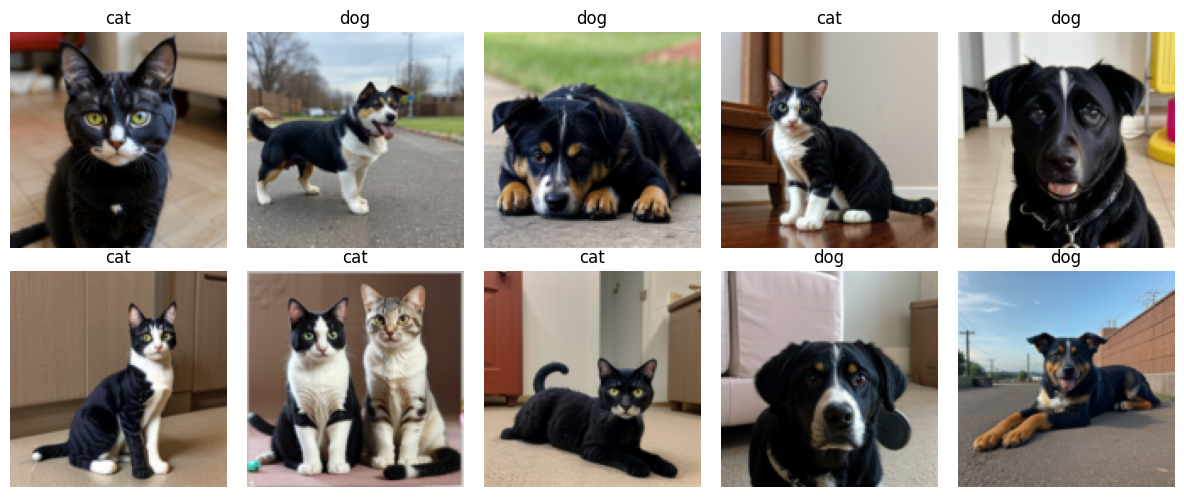

In [24]:
plt.figure(figsize=(12,5))
indices = np.random.randint(0, len(train_dataset), 10)

for i, idx in enumerate(indices):
    img, label = train_dataset[idx]
    img = img.numpy().transpose((1,2,0))

    plt.subplot(2,5,i+1)
    plt.imshow(img)
    plt.title(class_names[label])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [25]:
def count_class_distribution(dataset, dataset_name):
    class_names = dataset.classes
    labels = [label for _, label in dataset]
    df = pd.DataFrame({'labels': labels})
    df['class_name'] = df['labels'].apply(lambda x: class_names[x])

    print(f"\nDistribusi jumlah data per kelas ({dataset_name}):")
    print(df['class_name'].value_counts())

count_class_distribution(train_dataset, "Train")
count_class_distribution(valid_dataset, "Valid")
count_class_distribution(test_dataset, "Test")


Distribusi jumlah data per kelas (Train):
class_name
cat    350
dog    350
Name: count, dtype: int64

Distribusi jumlah data per kelas (Valid):
class_name
cat    75
dog    75
Name: count, dtype: int64

Distribusi jumlah data per kelas (Test):
class_name
cat    75
dog    75
Name: count, dtype: int64


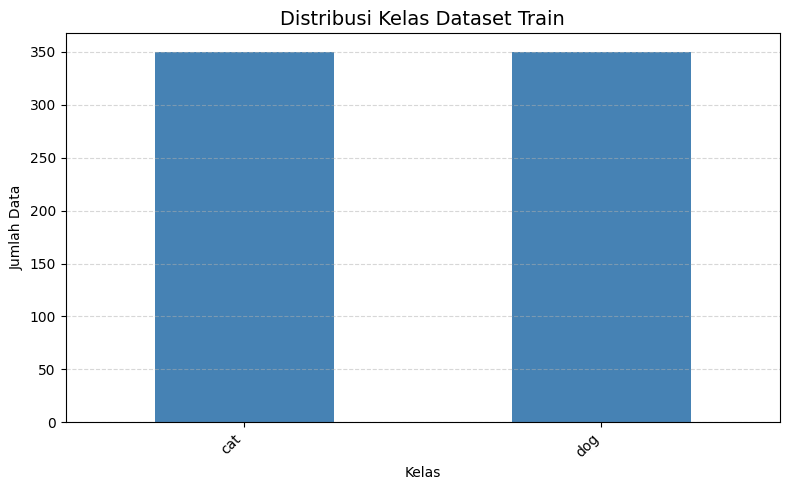

In [26]:
train_labels = train_dataset.targets
train_df = pd.DataFrame({'label_index': train_labels})
train_df['class_name'] = train_df['label_index'].apply(lambda x: class_names[x])
train_dist = train_df['class_name'].value_counts()
plt.figure(figsize=(8, 5))

# Urutkan dan plot
train_dist.sort_values(ascending=False).plot(kind='bar', color='steelblue')

plt.title('Distribusi Kelas Dataset Train', fontsize=14)
plt.xlabel('Kelas')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## **MULTILAYER PERCEPTRON (MLP)**

In [27]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=64, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False)

In [28]:
# Checking the dataset
for images, labels in train_loader:
    print('Image batch dimensions:', images.shape)
    print('Image label dimensions:', labels.shape)
    print('Class labels of 10 examples:', labels[:10])
    break

Image batch dimensions: torch.Size([64, 3, 128, 128])
Image label dimensions: torch.Size([64])
Class labels of 10 examples: tensor([1, 0, 0, 1, 1, 1, 0, 1, 0, 0])


In [29]:
for i, (imgs, targets) in enumerate(train_dataset):
    print(imgs.shape)

    if i > 2:
        break

torch.Size([3, 128, 128])
torch.Size([3, 128, 128])
torch.Size([3, 128, 128])
torch.Size([3, 128, 128])


In [30]:
@torch.no_grad()    # Tell PyTorch to exclude the gradient calculations
def get_inference(model, type):
    """Get the model accuracy"""
    # Get the data loader
    data_loader = {
        'train': train_loader,
        'valid': valid_loader,
        'test': test_loader
    }[type]

    correct_pred, num_samples, loss = 0, 0, 0.

    model.eval()
    device = next(model.parameters()).device  # Get the model's device
    for i, (imgs, targets) in enumerate(data_loader):
        # Move data to the same device as the model
        imgs, targets = imgs.to(device), targets.to(device)

        # Predict
        logits = model(imgs)
        probs = F.softmax(logits, dim=1)
        _, preds = torch.max(probs, 1)

        # Calculate acc & loss
        correct_pred += (preds == targets).sum()
        num_samples += targets.size(0)
        loss += targets.size(0) * F.cross_entropy(logits, targets)

    # Find the mean loss & acc
    loss = loss / num_samples
    acc = 100 * correct_pred.float()/num_samples

    return acc, loss

In [31]:
def train(model, max_epoch, train_loader, optimizer):
    """Train the model"""
    # Initialize
    train_acc_list = []
    valid_acc_list = []
    losses = []

    # Get model device
    device = next(model.parameters()).device

    # Start iteration
    start_time = time.time()
    for epoch in range(max_epoch):
        # Training iterate over batch
        model.train()
        for batch_idx, (imgs, targets) in enumerate(train_loader):
            # Move data to the same device as the model
            imgs, targets = imgs.to(device), targets.to(device)

            # Forward pass
            logits = model(imgs)
            loss = F.cross_entropy(logits, targets)

            # Backpropagation
            model.zero_grad(set_to_none=True)
            loss.backward()

            # Update the model parameter
            optimizer.step()

            # Log the minibatch (inner iteration)
            losses.append(loss.item())
            if not batch_idx % int(len(train_loader)/2.):
                print(f'Epoch: {epoch+1:03d}/{max_epoch:03d} '
                      f'| Batch: {batch_idx:04d}/{len(train_loader):04d} '
                      f'| Loss: {loss:.4f}')

        # Inference
        model.eval()
        with torch.no_grad():
            train_acc, _ = get_inference(model, 'train')
            valid_acc, _ = get_inference(model, 'valid')

            print(f'Epoch: {epoch+1:03d}/{max_epoch:03d} '
                  f'| Train: {train_acc:.2f}% '
                  f'| Valid: {valid_acc:.2f}%')
            print('')

            train_acc_list.append(train_acc.item())
            valid_acc_list.append(valid_acc.item())

    # Finalize
    elapsed = (time.time() - start_time)/60
    print(f'Total Training Time: {elapsed:.2f} min')

    return losses, train_acc_list, valid_acc_list

In [32]:
@dataclass
class ModelConfig:
    # Config model
    n_in: int = 3 * 128 * 128     # 12288
    n_hidden: int = 50
    n_out: int = 2                 # 2 kelas: cat dan dog
    drop_proba: float = 0.4

    # Config train
    lr: float = 1e-4
    max_epochs: int = 50
    batch_size: int = 64

In [33]:
CONFIG = ModelConfig()
CONFIG

ModelConfig(n_in=49152, n_hidden=50, n_out=2, drop_proba=0.4, lr=0.0001, max_epochs=50, batch_size=64)

In [34]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [35]:
class DeeperMLP(nn.Module):
    """
    MLP yang Lebih Dalam dengan Dua Lapisan Tersembunyi dan Dropout.
    """
    def __init__(self, config):
        super().__init__()

        # Inisialisasi agar dapat direproduksi
        torch.manual_seed(42)

        # Menggunakan node yang lebih banyak untuk lapisan tersembunyi
        self.n_hidden_1 = 4 * config.n_hidden  # 4 * 50 = 200 node
        self.n_hidden_2 = 2 * config.n_hidden  # 2 * 50 = 100 node

        self.model = nn.Sequential(
            # Flatten
            nn.Flatten(),

            # 1st hidden layer
            nn.Linear(config.n_in, self.n_hidden_1),
            nn.ReLU(),
            nn.Dropout(config.drop_proba),

            # 2nd hidden layer
            nn.Linear(self.n_hidden_1, self.n_hidden_2),
            nn.ReLU(),

            # 3rd hidden layer
            nn.Linear(self.n_hidden_2, config.n_out)
        )

    def forward(self, X):
        return self.model(X)

model_mlp_deeper = DeeperMLP(CONFIG)

print('Total parameters Deeper MLP:', sum(p.nelement() for p in model_mlp_deeper.parameters()))

Total parameters Deeper MLP: 9850902


In [36]:
# Initialize models
model_mlp = DeeperMLP(CONFIG)

# Print number of parameters
print('Total parameters :', sum(p.nelement() for p in model_mlp.parameters()))

Total parameters : 9850902


In [37]:
# Define optimizer
optimizer_1 = torch.optim.Adam(params=model_mlp.parameters(),
                               lr=CONFIG.lr)

In [ ]:
losses_mlp, train_acc_mlp, valid_acc_mlp = train(model=model_mlp,
                                                 max_epoch=CONFIG.max_epochs,
                                                 train_loader=train_loader,
                                                 optimizer=optimizer_1)

Epoch: 001/050 | Batch: 0000/0011 | Loss: 0.6931
Epoch: 001/050 | Batch: 0005/0011 | Loss: 0.6875
Epoch: 001/050 | Batch: 0010/0011 | Loss: 0.6604
Epoch: 001/050 | Train: 64.00% | Valid: 61.33%

Epoch: 002/050 | Batch: 0000/0011 | Loss: 0.6843
Epoch: 002/050 | Batch: 0005/0011 | Loss: 0.6883
Epoch: 002/050 | Batch: 0010/0011 | Loss: 0.5334
Epoch: 002/050 | Train: 68.14% | Valid: 66.00%

Epoch: 003/050 | Batch: 0000/0011 | Loss: 0.4865
Epoch: 003/050 | Batch: 0005/0011 | Loss: 0.5538
Epoch: 003/050 | Batch: 0010/0011 | Loss: 0.5732
Epoch: 003/050 | Train: 76.57% | Valid: 72.00%

Epoch: 004/050 | Batch: 0000/0011 | Loss: 0.5144
Epoch: 004/050 | Batch: 0005/0011 | Loss: 0.6716
Epoch: 004/050 | Batch: 0010/0011 | Loss: 0.5007


In [ ]:
plt.plot(np.arange(len(losses_mlp)), losses_mlp, c='tab:blue', label='minibatch loss')
plt.legend()
plt.show()

In [ ]:
# simple plot (auto y-limits)
plt.figure(figsize=(7,4))
plt.plot(np.arange(len(train_acc_mlp)), train_acc_mlp, c='tab:blue', label='train')
plt.plot(np.arange(len(valid_acc_mlp)), valid_acc_mlp, c='tab:orange', label='valid')
plt.ylabel('% Accuracy')
plt.xlabel('Epoch')
plt.ylim(0, 100)     # akurasi dalam 0-100
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Calculate
train_acc_mlp, train_loss_mlp = get_inference(model_mlp, 'train')
valid_acc_mlp, valid_loss_mlp = get_inference(model_mlp, 'valid')
test_acc_mlp, test_loss_mlp = get_inference(model_mlp, 'test')

In [ ]:
# Summarize in dataframe
summary_df = pd.DataFrame(
    np.array([[train_acc_mlp, valid_acc_mlp, test_acc_mlp, train_loss_mlp, valid_loss_mlp, test_loss_mlp]]),
    index = ['MLP'],
    columns = ['Train Acc', 'Valid Acc', 'Test Acc', 'Train Loss', 'Valid Loss', 'Test Loss']
)

summary_df

In [ ]:
# Mapping label sesuai ImageFolder
class_names = train_dataset.classes
labels_map = {i: name for i, name in enumerate(class_names)}
print(labels_map)

In [ ]:
# Ambil batch dari validation set
X_samples, y_samples = next(iter(valid_loader))

In [ ]:
# Get prediction
model_mlp.eval()
with torch.no_grad():
    logits_sample = model_mlp(X_samples)
    probs_sample = F.softmax(logits_sample, dim=1)
    y_samples_pred = probs_sample.max(1, keepdim=True)[1].view(-1)

y_samples_pred

In [ ]:
fig, axes = plt.subplots(ncols=8, nrows=4, figsize=(14, 8))
index = 0

for i in range(4):
    for j in range(8):
        ax = axes[i, j]

        # Ambil label asli & prediksi
        act_label = labels_map[y_samples[index].item()]
        pred_label = labels_map[y_samples_pred[index].item()]

        # Warna judul
        color = 'g' if act_label == pred_label else 'r'

        # Convert tensor ke numpy dan transpose (C,H,W -> H,W,C)
        img = X_samples[index].permute(1, 2, 0).numpy()
        img = img.clip(0, 1)

        ax.imshow(img)
        ax.set_title(f'act: {act_label}\npred: {pred_label}',
                     color=color, fontsize=8)
        ax.axis('off')

        index += 1

plt.tight_layout()
plt.show()

## **CONVOLUTIONAL NEURAL NETWORK**

In [ ]:
class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()

        FINAL_CHANNELS = 256
        NUM_CLASSES = 2  # 2 kelas: cat dan dog

        self.features = nn.Sequential(
            # Conv Block 1
            nn.Conv2d(3, 8, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(8),
            nn.MaxPool2d(2),
            nn.Dropout(0.3),

            # Conv Block 2
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Conv Block 3
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Conv Block 4
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Conv Block 5
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Conv Block 6 (Output Channel: 256)
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),

            # Lapisan Dense (Linear) pertama setelah GAP
            nn.Linear(FINAL_CHANNELS, 512),
            nn.ReLU(),
            nn.Dropout(0.4),

            # Lapisan Output
            nn.Linear(512, NUM_CLASSES)
        )

    def forward(self, x):

        # Ekstraksi Fitur
        x = self.features(x)

        # Global Average Pooling
        x = self.global_pool(x)

        # Klasifikasi
        x = self.classifier(x)

        return x

model_cnn = CNNModel()
print('Total parameters CNN:', sum(p.nelement() for p in model_cnn.parameters()))

Total parameters CNN: 1312338


In [ ]:
model_cnn = CNNModel().to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model_cnn.parameters(), lr=1e-4, weight_decay=1e-4)

In [ ]:
losses_cnn, train_acc_cnn, valid_acc_cnn = train(
    model=model_cnn,
    max_epoch=CONFIG.max_epochs,
    train_loader=train_loader,
    optimizer=optimizer
)

Epoch: 001/050 | Batch: 0000/0011 | Loss: 0.6926
Epoch: 001/050 | Batch: 0005/0011 | Loss: 0.6989
Epoch: 001/050 | Batch: 0010/0011 | Loss: 0.6967
Epoch: 001/050 | Train: 50.00% | Valid: 50.00%

Epoch: 002/050 | Batch: 0000/0011 | Loss: 0.6897
Epoch: 002/050 | Batch: 0005/0011 | Loss: 0.6959
Epoch: 002/050 | Batch: 0010/0011 | Loss: 0.6876
Epoch: 002/050 | Train: 50.00% | Valid: 50.00%

Epoch: 003/050 | Batch: 0000/0011 | Loss: 0.6965
Epoch: 003/050 | Batch: 0005/0011 | Loss: 0.6921
Epoch: 003/050 | Batch: 0010/0011 | Loss: 0.6932
Epoch: 003/050 | Train: 50.00% | Valid: 50.00%

Epoch: 004/050 | Batch: 0000/0011 | Loss: 0.6927
Epoch: 004/050 | Batch: 0005/0011 | Loss: 0.6949
Epoch: 004/050 | Batch: 0010/0011 | Loss: 0.6887
Epoch: 004/050 | Train: 50.29% | Valid: 50.67%

Epoch: 005/050 | Batch: 0000/0011 | Loss: 0.6936
Epoch: 005/050 | Batch: 0005/0011 | Loss: 0.6838
Epoch: 005/050 | Batch: 0010/0011 | Loss: 0.7115
Epoch: 005/050 | Train: 50.00% | Valid: 50.00%

Epoch: 006/050 | Batch: 0

In [ ]:
train_acc, train_loss = get_inference(model_cnn, 'train')
valid_acc, valid_loss = get_inference(model_cnn, 'valid')
test_acc, test_loss = get_inference(model_cnn, 'test')

summary_df.loc['CNN'] = np.array([
    train_acc.cpu(), valid_acc.cpu(), test_acc.cpu(),
    train_loss.cpu(), valid_loss.cpu(), test_loss.cpu()
])

summary_df

,Train Acc,Valid Acc,Test Acc,Train Loss,Valid Loss,Test Loss
MLP,99.000000,78.666664,83.333336,0.063536,0.526446,0.485863
CNN,94.142853,88.666672,86.666672,0.133666,0.303605,0.337926


In [ ]:
# Ambil batch valid
X_samples, y_samples = next(iter(valid_loader))

# Dapatkan device tempat model berada
device = next(model_cnn.parameters()).device

# Prediksi menggunakan CNN
model_cnn.eval()
with torch.no_grad():
    # Pindahkan input ke device yang sama dengan model
    logits_sample = model_cnn(X_samples.to(device))
    probs_sample = F.softmax(logits_sample, dim=1)
    y_samples_pred = probs_sample.argmax(dim=1)

y_samples_pred

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')

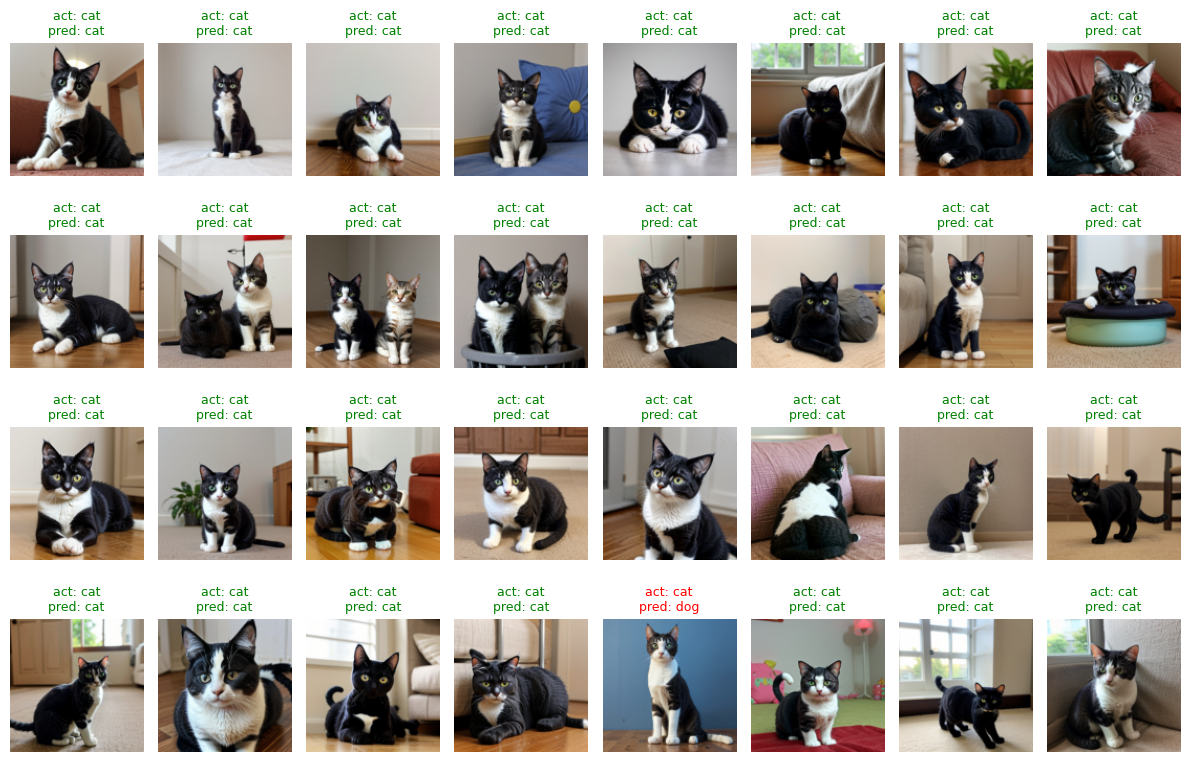

In [ ]:
# labels_map otomatis dari folder
labels_map = {i: class_names[i] for i in range(len(class_names))}

fig, axes = plt.subplots(ncols=8, nrows=4, figsize=(12, 8))
index = 0

for i in range(4):
    for j in range(8):

        act_label = labels_map[y_samples[index].item()]
        pred_label = labels_map[y_samples_pred[index].item()]
        color = 'g' if act_label == pred_label else 'r'

        axes[i,j].set_title(
            f'act: {act_label}\npred: {pred_label}',
            color=color, size=9
        )

        axes[i,j].imshow(X_samples[index].permute(1, 2, 0))  # RGB
        axes[i,j].axis('off')

        index += 1

plt.tight_layout()
plt.show()

In [ ]:
print(len(losses_cnn))
print(len(train_acc_cnn))
print(len(valid_acc_cnn))

550
50
50


In [ ]:
# Hitung rata-rata loss per epoch
n_batches = len(train_loader)
losses_per_epoch = np.array(losses_cnn).reshape(CONFIG.max_epochs, -1).mean(axis=1) if len(losses_cnn) % CONFIG.max_epochs == 0 else [np.mean(losses_cnn[i*n_batches:(i+1)*n_batches]) for i in range(CONFIG.max_epochs)]

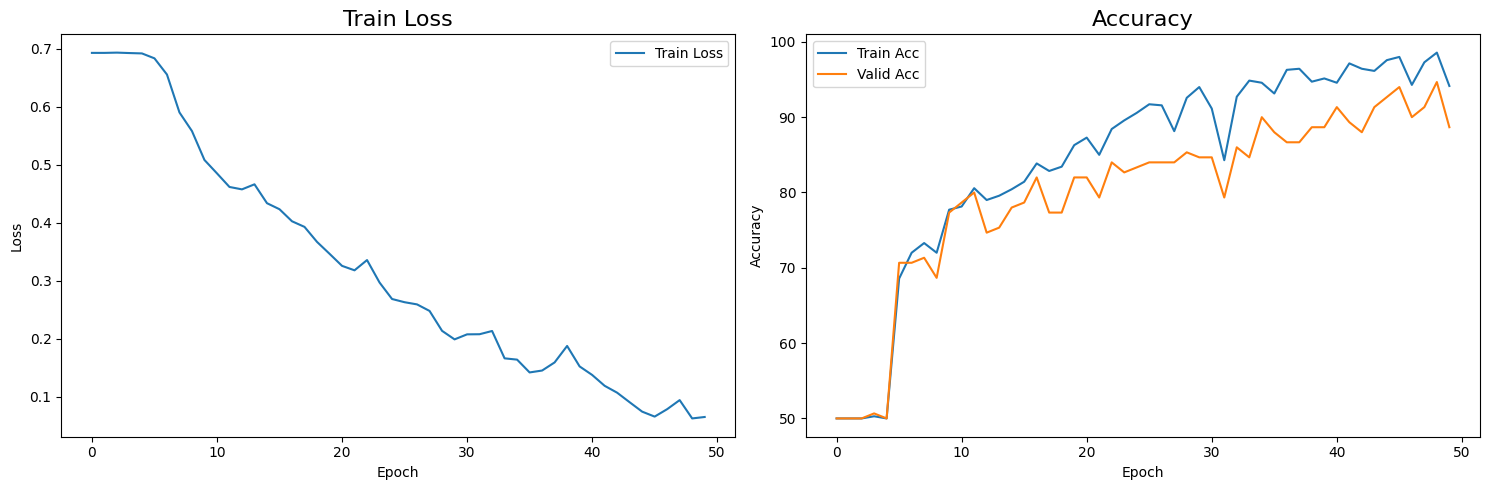

In [ ]:
hist_cnn = pd.DataFrame({
    "loss": losses_per_epoch,
    "train_acc": train_acc_cnn,
    "valid_acc": valid_acc_cnn
})

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(hist_cnn['loss'], label='Train Loss')
plt.title('Train Loss', fontsize=16)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_cnn['train_acc'], label='Train Acc')
plt.plot(hist_cnn['valid_acc'], label='Valid Acc')
plt.title('Accuracy', fontsize=16)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
def get_full_predictions(model, data_loader, device):

    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)

            outputs = model(inputs)

            _, preds = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    return np.array(y_true), np.array(y_pred)

y_true_test, y_pred_test = get_full_predictions(model_cnn, test_loader, device)

print("CLASSIFICATION REPORT\n")
print(classification_report(y_true_test, y_pred_test, target_names=class_names))

CLASSIFICATION REPORT

              precision    recall  f1-score   support

         cat       0.81      0.96      0.88        75
         dog       0.95      0.77      0.85        75

    accuracy                           0.87       150
   macro avg       0.88      0.87      0.87       150
weighted avg       0.88      0.87      0.87       150



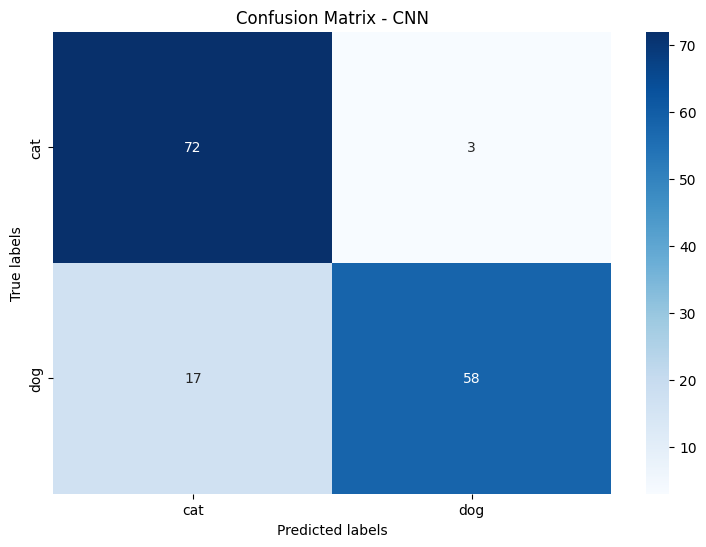

In [ ]:
CM = confusion_matrix(y_true_test, y_pred_test)

plt.figure(figsize=(9, 6))
sns.heatmap(
    CM,
    annot=True,
    fmt='g',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix - CNN')
plt.show()

In [ ]:
def predict_image(model, image_path, class_names, device='cuda'):
    model.eval()

    # Load and preprocess
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Resize ke ukuran dataset (128x128)
    img_resized = cv2.resize(img, (128, 128))

    # Convert ke tensor (C,H,W) dan normalisasi ke [0,1]
    img_tensor = torch.tensor(img_resized, dtype=torch.float32).permute(2, 0, 1) / 255.0
    img_tensor = img_tensor.unsqueeze(0).to(device)

    # Predict
    with torch.no_grad():
        logits = model(img_tensor)
        pred_class = logits.argmax(dim=1).cpu().item()

    predicted_label = class_names[pred_class]

    # Plot
    plt.figure(figsize=(4,4))
    plt.imshow(img_resized)
    plt.title(predicted_label)
    plt.axis('off')
    plt.show()

    return predicted_label

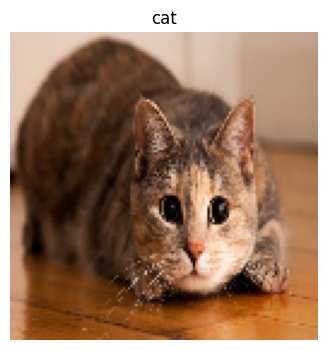

'cat'

In [ ]:
# Pengujian prediksi menggunakan gambar dari internet
sample_image = '/content/Kucing-1.jpg'

predict_image(
    model=model_cnn,
    image_path=sample_image,
    class_names=class_names,
    device=device
)

## **RESIDUAL NETWORK (RESNET)-18**
---
ResNet diperkenalkan oleh Microsoft Research (He et al., 2015) dan terkenal karena konsep skip connection / residual connection, yang membantu mengatasi masalah vanishing gradient pada jaringan deep learning yang sangat dalam.

In [ ]:
def train(model, max_epoch, train_loader, optimizer, criterion): # <--- PERBAIKAN 1: TAMBAH ARGUMEN CRITERION
    """Train the model"""
    # Initialize
    train_acc_list = []
    valid_acc_list = []
    losses = []

    # Start iteration
    start_time = time.time()
    for epoch in range(max_epoch):
        model.train()
        for batch_idx, (imgs, targets) in enumerate(train_loader):
            # Forward pass
            logits = model(imgs)

            # Hitung loss menggunakan criterion
            loss = criterion(logits, targets)

            # Backpropagation
            model.zero_grad(set_to_none=True)
            loss.backward()

            # Update the model parameter
            optimizer.step()
            losses.append(loss.item())
            if not batch_idx % int(len(train_loader)/2.):
                print(f'Epoch: {epoch+1:03d}/{max_epoch:03d} '
                      f'| Batch: {batch_idx:04d}/{len(train_loader):04d} '
                      f'| Loss: {loss:.4f}')

        # Inference
        model.eval()
        with torch.no_grad():
            train_acc, _ = get_inference(model, 'train')
            valid_acc, _ = get_inference(model, 'valid')

            print(f'Epoch: {epoch+1:03d}/{max_epoch:03d} '
                  f'| Train: {train_acc:.2f}% '
                  f'| Valid: {valid_acc:.2f}%')
            print('')

            train_acc_list.append(train_acc.item())
            valid_acc_list.append(valid_acc.item())

    # Finalize
    elapsed = (time.time() - start_time)/60
    print(f'Total Training Time: {elapsed:.2f} min')

    return losses, train_acc_list, valid_acc_list

In [ ]:
# Memuat arsitektur Pre-trained ResNet-18 dan bobot yang dilatih di ImageNet
model_resnet18 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Ganti Lapisan Fully Connected (Classifier)
num_ftrs = model_resnet18.fc.in_features
model_resnet18.fc = nn.Sequential(
    nn.Dropout(CONFIG.drop_proba),
    nn.Linear(num_ftrs, CONFIG.n_out)
)

# Pindahkan model ke device
model_resnet = model_resnet18.to(device)
print(f"Total parameters ResNet-18 Pre-trained: {sum(p.nelement() for p in model_resnet.parameters())}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 57.7MB/s]


Total parameters ResNet-18 Pre-trained: 11177538


In [ ]:
# Data Distribusi
from collections import Counter
train_counts = Counter(train_dataset.targets)
class_counts = {class_names[idx]: train_counts[idx] for idx in range(len(class_names))}
print("Distribusi kelas data train:", class_counts)

total_samples = sum(class_counts.values())
class_names_ordered = class_names # ['cat', 'dog']

counts = np.array([class_counts[name] for name in class_names_ordered])
weights = total_samples / counts
weights_normalized = weights / np.sum(weights)

class_weights = torch.tensor(weights_normalized, dtype=torch.float32).to(device)

# Criterion Weighted
criterion_weighted = nn.CrossEntropyLoss(weight=class_weights)

# OPTIMIZER
optimizer_resnet = torch.optim.Adam(
    model_resnet18.parameters(),
    lr=CONFIG.lr,
    weight_decay=1e-4
)

Distribusi kelas data train: {'cat': 350, 'dog': 350}


Epoch: 001/050 | Batch: 0000/0011 | Loss: 0.6091
Epoch: 001/050 | Batch: 0005/0011 | Loss: 0.0555
Epoch: 001/050 | Batch: 0010/0011 | Loss: 0.0288
Epoch: 001/050 | Train: 100.00% | Valid: 98.00%

Epoch: 002/050 | Batch: 0000/0011 | Loss: 0.0173
Epoch: 002/050 | Batch: 0005/0011 | Loss: 0.0039
Epoch: 002/050 | Batch: 0010/0011 | Loss: 0.0018
Epoch: 002/050 | Train: 100.00% | Valid: 98.67%

Epoch: 003/050 | Batch: 0000/0011 | Loss: 0.0035
Epoch: 003/050 | Batch: 0005/0011 | Loss: 0.0019
Epoch: 003/050 | Batch: 0010/0011 | Loss: 0.0007
Epoch: 003/050 | Train: 100.00% | Valid: 98.67%

Epoch: 004/050 | Batch: 0000/0011 | Loss: 0.0005
Epoch: 004/050 | Batch: 0005/0011 | Loss: 0.0004
Epoch: 004/050 | Batch: 0010/0011 | Loss: 0.0012
Epoch: 004/050 | Train: 100.00% | Valid: 98.67%

Epoch: 005/050 | Batch: 0000/0011 | Loss: 0.0006
Epoch: 005/050 | Batch: 0005/0011 | Loss: 0.0049
Epoch: 005/050 | Batch: 0010/0011 | Loss: 0.0002
Epoch: 005/050 | Train: 100.00% | Valid: 99.33%

Epoch: 006/050 | Bat

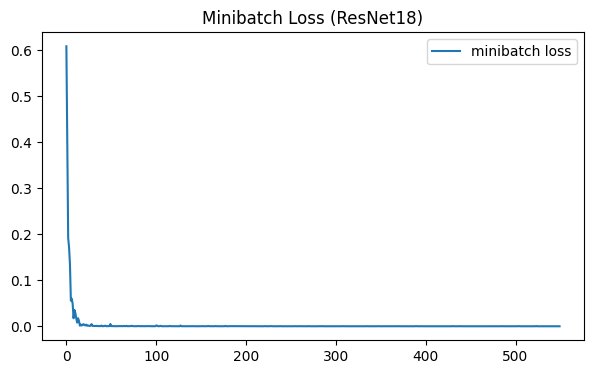

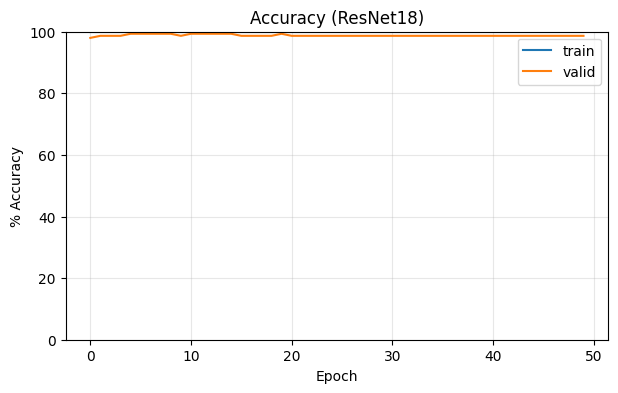

In [ ]:
# Dapatkan device aktif tempat model berada
device = next(model_resnet18.parameters()).device

# Modifikasi lokal fungsi train agar memindahkan data ke device sebelum forward pass
def train_with_device(model, max_epoch, train_loader, optimizer, criterion, device):
    train_acc_list = []
    valid_acc_list = []
    losses = []
    start_time = time.time()

    for epoch in range(max_epoch):
        model.train()
        for batch_idx, (imgs, targets) in enumerate(train_loader):
            # Pindahkan data ke device (GPU)
            imgs, targets = imgs.to(device), targets.to(device)

            # Forward pass
            logits = model(imgs)
            loss = criterion(logits, targets)

            # Backpropagation
            model.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            losses.append(loss.item())
            if not batch_idx % int(len(train_loader)/2.):
                print(f'Epoch: {epoch+1:03d}/{max_epoch:03d} '
                      f'| Batch: {batch_idx:04d}/{len(train_loader):04d} '
                      f'| Loss: {loss:.4f}')

        # Inference
        model.eval()
        with torch.no_grad():
            train_acc, _ = get_inference(model, 'train')
            valid_acc, _ = get_inference(model, 'valid')
            print(f'Epoch: {epoch+1:03d}/{max_epoch:03d} | Train: {train_acc:.2f}% | Valid: {valid_acc:.2f}%\n')
            train_acc_list.append(train_acc.item())
            valid_acc_list.append(valid_acc.item())

    elapsed = (time.time() - start_time)/60
    print(f'Total Training Time: {elapsed:.2f} min')
    return losses, train_acc_list, valid_acc_list

# Lakukan Training ResNet dengan Weighted Criterion menggunakan fungsi yang sudah diperbaiki
losses_resnet, train_acc_resnet, valid_acc_resnet = train_with_device(
    model=model_resnet18,
    max_epoch=CONFIG.max_epochs,
    train_loader=train_loader,
    optimizer=optimizer_resnet,
    criterion=criterion_weighted,
    device=device
)

# Plot Loss
plt.figure(figsize=(7,4))
plt.plot(np.arange(len(losses_resnet)), losses_resnet, c='tab:blue', label='minibatch loss')
plt.legend()
plt.title('Minibatch Loss (ResNet18)')
plt.show()

# Plot Accuracy
plt.figure(figsize=(7,4))
plt.plot(np.arange(len(train_acc_resnet)), train_acc_resnet, c='tab:blue', label='train')
plt.plot(np.arange(len(valid_acc_resnet)), valid_acc_resnet, c='tab:orange', label='valid')
plt.ylabel('% Accuracy')
plt.xlabel('Epoch')
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.title('Accuracy (ResNet18)')
plt.show()

In [ ]:
# Hitung metrik akhir
train_acc, train_loss = get_inference(model_resnet18, 'train')
valid_acc, valid_loss = get_inference(model_resnet18, 'valid')
test_acc, test_loss = get_inference(model_resnet18, 'test')

# Tambahkan metrik ke DataFrame dengan indeks baru
summary_df.loc['ResNet18'] = np.array([
    train_acc.item(),
    valid_acc.item(),
    test_acc.item(),
    train_loss.item(),
    valid_loss.item(),
    test_loss.item()
])

summary_df

,Train Acc,Valid Acc,Test Acc,Train Loss,Valid Loss,Test Loss
MLP,99.000000,78.666664,83.333336,0.063536,0.526446,0.485863
CNN,94.142853,88.666672,86.666672,0.133666,0.303605,0.337926
ResNet18,100.000000,98.666672,100.000000,0.000012,0.051197,0.001851


In [ ]:
# Ambil batch valid
X_samples, y_samples = next(iter(valid_loader))

# Dapatkan device aktif tempat model berada
device = next(model_resnet18.parameters()).device

# Prediksi menggunakan ResNet18
model_resnet18.eval()
with torch.no_grad():
    # Pindahkan input ke device yang sama dengan model
    logits_sample = model_resnet18(X_samples.to(device))
    probs_sample = F.softmax(logits_sample, dim=1)
    y_samples_pred = probs_sample.argmax(dim=1)

y_samples_pred

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')

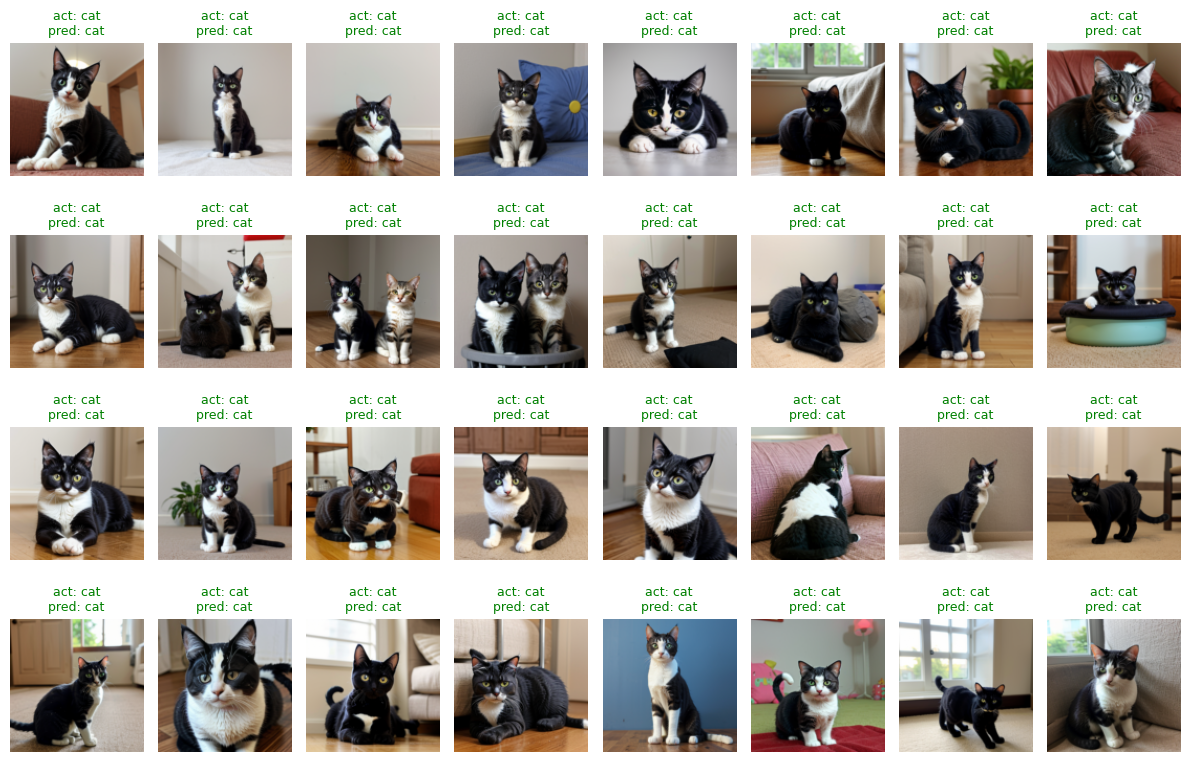

In [ ]:
# labels_map otomatis dari folder
labels_map = {i: class_names[i] for i in range(len(class_names))}

fig, axes = plt.subplots(ncols=8, nrows=4, figsize=(12, 8))
index = 0

for i in range(4):
    for j in range(8):

        act_label = labels_map[y_samples[index].item()]
        pred_label = labels_map[y_samples_pred[index].item()]

        color = 'g' if act_label == pred_label else 'r'

        axes[i,j].set_title(
            f'act: {act_label}\npred: {pred_label}',
            color=color, size=9
        )

        axes[i,j].imshow(X_samples[index].permute(1, 2, 0))
        axes[i,j].axis('off')

        index += 1

plt.tight_layout()
plt.show()

In [ ]:
def get_full_predictions(model, data_loader, device):

    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)

            outputs = model(inputs)

            _, preds = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    return np.array(y_true), np.array(y_pred)

y_true_test, y_pred_test = get_full_predictions(model_resnet18, test_loader, device)

print("CLASSIFICATION REPORT\n")
print(classification_report(y_true_test, y_pred_test, target_names=class_names))

CLASSIFICATION REPORT

              precision    recall  f1-score   support

         cat       1.00      1.00      1.00        75
         dog       1.00      1.00      1.00        75

    accuracy                           1.00       150
   macro avg       1.00      1.00      1.00       150
weighted avg       1.00      1.00      1.00       150



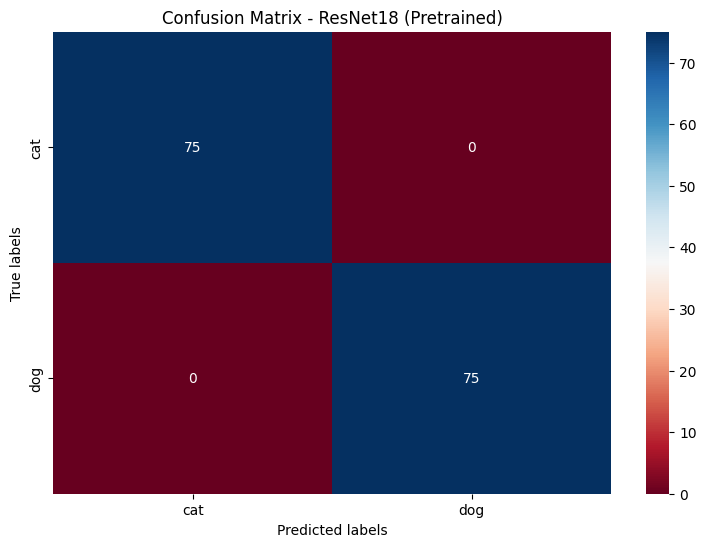

In [ ]:
CM = confusion_matrix(y_true_test, y_pred_test)

plt.figure(figsize=(9, 6))
sns.heatmap(
    CM,
    annot=True,
    fmt='g',
    cmap='RdBu',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix - ResNet18 (Pretrained)')
plt.show()

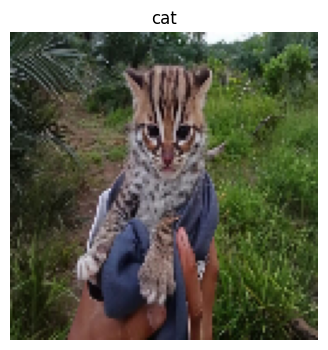

'cat'

In [ ]:
# Pengujian prediksi menggunakan gambar dari internet
import requests

# URL gambar dari internet
image_url = "https://indomgb.s3.amazonaws.com/wp-content/uploads/2026/09/29040912/Kucing-kuwuk2-768x512.jpeg"

# Mengambil gambar dari URL
response = requests.get(image_url)
response.raise_for_status()

# Menyimpan sementara gambar
sample_image = '/content/temp_image.jpg'

with open(sample_image, 'wb') as f:
    f.write(response.content)

# Prediksi gambar
predict_image(
    model=model_cnn,
    image_path=sample_image,
    class_names=class_names,
    device=device
)